# v5_greedy — 탐욕적 변수선택 (Forward-Backward Add/Drop) — 증분신호 일반화

**질문.** 지금까지 수집한 변수들(31개)을 greedy하게 **넣었다 뺐다** 하면, 어떤 변수가
실제로 증분 신호를 갖고 어떤 변수가 잉여/공선인가? 손으로 고른 **v3c(14개)** 가 맞는 세트인가?

**방법 (EV 게이트의 일반화).** 빈 세트에서 시작해 매 라운드 forward(추가)+backward(제거):
- **선택 구동 = AIC + 계수 p + VIF** (전부 학습 내 지표). ADD 게이트 `ΔAIC<−2 & p<0.05 & VIF<10`.
- **2025 MAE는 게이트가 아니라 OOS 확인용**으로만 기록. 선택 루프가 홀드아웃을 반복 엿보면
  누수가 되어 헤드라인 MAE가 낙관 편향됨 → 2025는 봉인.
- **window(학습 시작연도) ∈ {2010, 2018, 2021}** 바깥 루프. 평가 2025 고정. 변수가
  *모든* window에서 뽑히면 견고한 구조 신호, *2021~에서만* 뽑히면 최근 레짐 신호(EV류).

- 산출 스크립트: `src/model_arimax_v5_greedy.py` / 결과: `data/processed/arimax/greedy_*.csv`
- 본모델·기존 노트북 불변. 경위: `docs/research_log/2026-05-30_*_탐욕적_변수선택_AddDrop.md`


In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import font_manager
import seaborn as sns

warnings.filterwarnings("ignore")

# 한글 폰트 (eda/modeling/v4_ev.ipynb와 동일)
NOTO_PATH = Path("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
if NOTO_PATH.exists():
    font_manager.fontManager.addfont(str(NOTO_PATH))
KOR_FONT = "Noto Sans CJK JP"
mpl.rcParams["font.family"] = KOR_FONT
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", rc={"font.family": KOR_FONT})

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed" / "arimax"
print("PROC:", PROC)

path = pd.read_csv(PROC / "greedy_selection_path.csv", encoding="utf-8-sig")
summ = pd.read_csv(PROC / "greedy_final_summary.csv", encoding="utf-8-sig")
mat  = pd.read_csv(PROC / "greedy_window_matrix.csv", encoding="utf-8-sig")
WINS = list(dict.fromkeys(path["window"]))
print("windows:", WINS, "| path rows:", len(path))

PROC: /home/jmlee/research/timeseries-final/data/processed/arimax
windows: ['2010~2024', '2018~2024', '2021~2024'] | path rows: 890


## 1. 선택 경로 — AIC 하강 (window별)

채택된 move만 순서대로. **AIC가 단조 하강**(선택 구동 지표)하고, 회색 **MAE_2025**(확인용)가
대체로 같이 내려가면 — 홀드아웃을 *엿보지 않고도* 선택이 OOS 성능을 따라간다는 뜻.


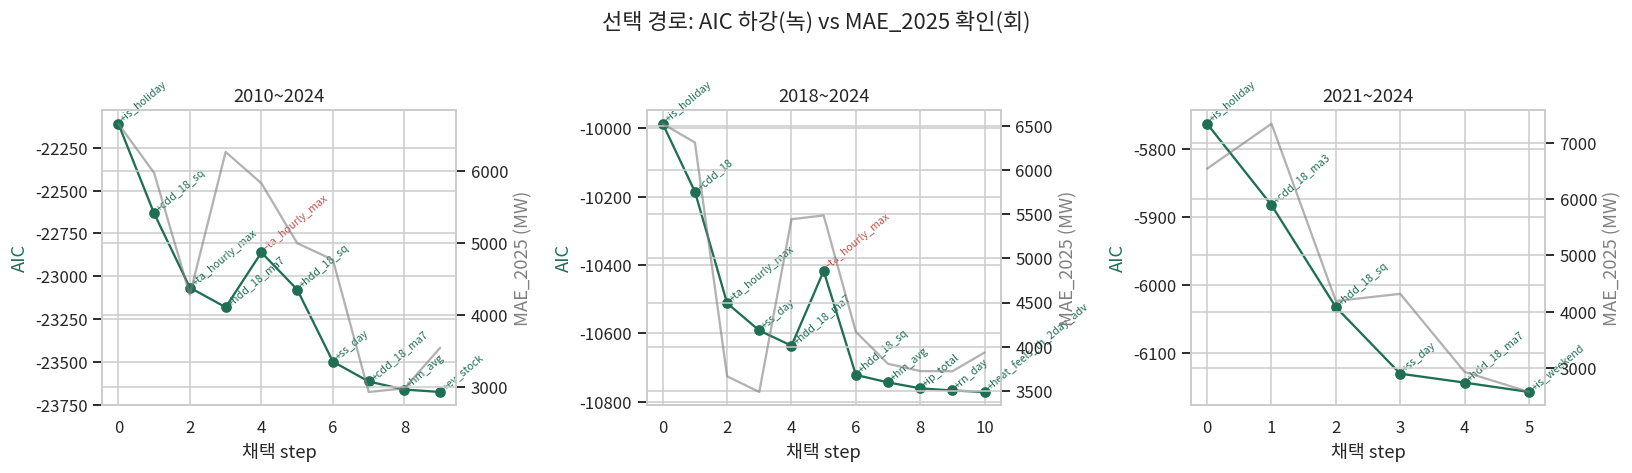

In [2]:
fig, axes = plt.subplots(1, len(WINS), figsize=(5*len(WINS), 4.2), squeeze=False)
for ax, w in zip(axes[0], WINS):
    acc = path[(path["window"] == w) & (path["accepted"] == True)].copy()  # noqa: E712
    acc = acc.reset_index(drop=True)
    xs = range(len(acc))
    ax.plot(xs, acc["AIC"], "-o", color="#1f6f54", lw=1.5, label="AIC")
    for i, r in acc.iterrows():
        sign = "+" if r["action"] == "add" else "−"
        ax.annotate(f"{sign}{r['var']}", (i, r["AIC"]), fontsize=7,
                    rotation=40, ha="left", va="bottom",
                    color="#1f6f54" if r["action"] == "add" else "#c0504d")
    ax.set_title(f"{w}")
    ax.set_xlabel("채택 step")
    ax.set_ylabel("AIC", color="#1f6f54")
    axb = ax.twinx()
    axb.plot(xs, acc["MAE_2025"], "-", color="gray", alpha=0.6, label="MAE_2025")
    axb.set_ylabel("MAE_2025 (MW)", color="gray")
fig.suptitle("선택 경로: AIC 하강(녹) vs MAE_2025 확인(회)", y=1.02)
plt.tight_layout()
plt.show()

## 2. 후보 게이트 현황 — 왜 떨어졌나

forward에서 평가된 **모든 add 후보**를 ΔAIC(x) × VIF(y)에 찍음. 점선이 게이트(`ΔAIC=−2`,
`VIF=10`). **왼쪽-아래 + p<0.05(녹)** 영역만 통과. 오른쪽/위로 벗어난 점은 공선(VIF↑) 또는
개선 부족(ΔAIC↑)으로 기각된 후보들 — EV류 추세 공선이 여기서 드러남.


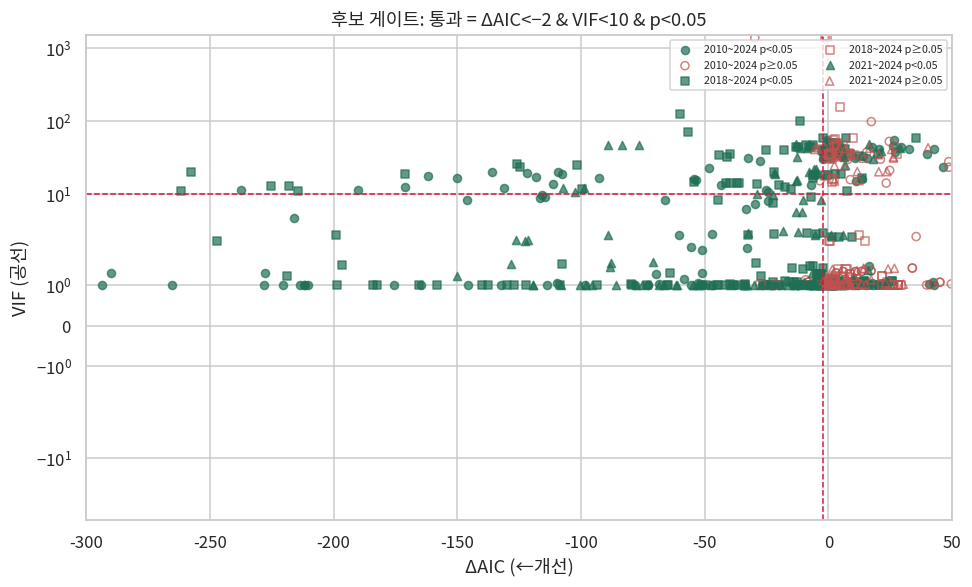

In [3]:
add = path[path["action"] == "add"].copy()
add = add[np.isfinite(add["dAIC"]) & np.isfinite(add["VIF"])]
markers = {w: mk for w, mk in zip(WINS, ["o", "s", "^", "D"])}

fig, ax = plt.subplots(figsize=(9, 5.5))
for w in WINS:
    sub = add[add["window"] == w]
    for sig, col in [(True, "#1f6f54"), (False, "#c0504d")]:
        s2 = sub[(sub["p"] < 0.05) == sig]
        ax.scatter(s2["dAIC"], s2["VIF"], marker=markers[w], s=28,
                   facecolor=col if sig else "none", edgecolor=col, alpha=0.7,
                   label=f"{w} {'p<0.05' if sig else 'p≥0.05'}")
ax.axvline(-2, color="crimson", ls="--", lw=1)
ax.axhline(10, color="crimson", ls="--", lw=1)
ax.set_xlabel("ΔAIC (←개선)")
ax.set_ylabel("VIF (공선)")
ax.set_yscale("symlog")
ax.set_title("후보 게이트: 통과 = ΔAIC<−2 & VIF<10 & p<0.05")
# x축 클립(극단 양수 ΔAIC가 시야 압축하므로)
lo = max(add["dAIC"].min(), -300)
ax.set_xlim(lo, min(add["dAIC"].max(), 50))
ax.legend(fontsize=7, ncol=2, loc="upper right")
plt.tight_layout()
plt.show()

## 3. window × 변수 선택 매트릭스 (핵심)

각 window에서 최종 채택된 변수. **모든 열에서 채택 = 견고한 구조 신호**, **2021~ 열에서만 채택
= 최근 레짐 신호**. 색은 계수 부호(녹=+, 적=−), 빈 칸은 미채택.


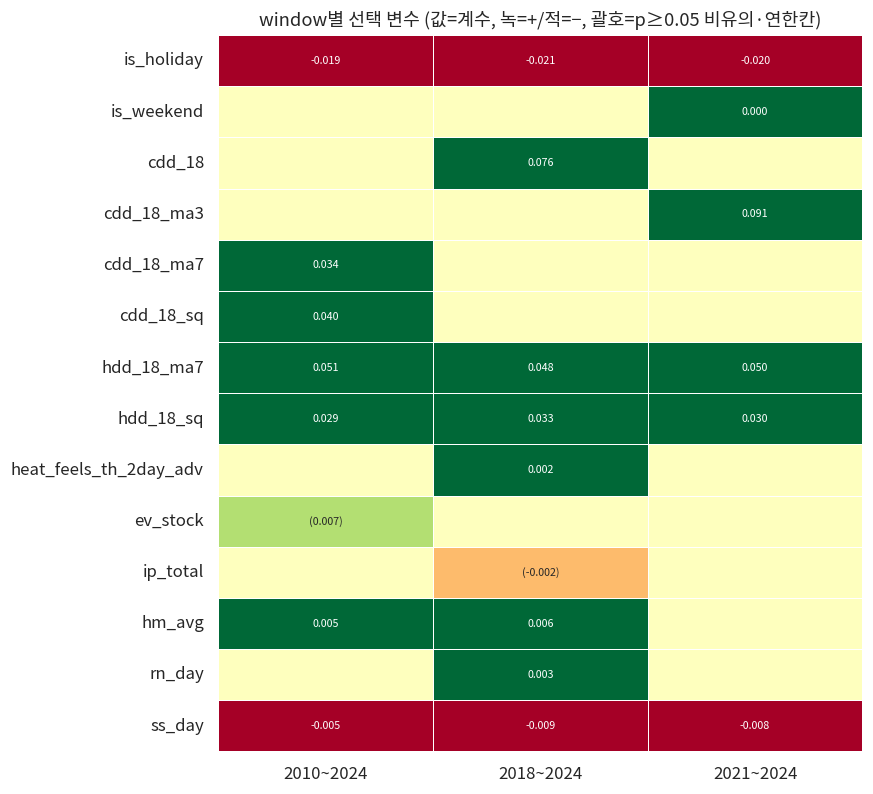

모든 window 채택: ['is_holiday', 'hdd_18_ma7', 'hdd_18_sq', 'ss_day']
  └ 그 중 전 window 유의(p<0.05) 견고핵심: ['is_holiday', 'hdd_18_ma7', 'hdd_18_sq', 'ss_day']
일부 window만 : {'is_weekend': 1, 'cdd_18': 1, 'cdd_18_ma3': 1, 'cdd_18_ma7': 1, 'cdd_18_sq': 1, 'heat_feels_th_2day_adv': 1, 'ev_stock': 1, 'ip_total': 1, 'hm_avg': 2, 'rn_day': 1}

채택됐으나 maxiter=200에서 비유의(검색-마진 artifact):
   window      var     p
2010~2024 ev_stock 0.823
2018~2024 ip_total 0.172


In [4]:
piv  = mat.pivot(index="var", columns="window", values="selected").fillna(0)
coef = mat.pivot(index="var", columns="window", values="coef")
pval = mat.pivot(index="var", columns="window", values="p")
# 한 번이라도 선택된 변수만, 클러스터 순으로
order = [v for v in mat["var"].unique() if piv.loc[v].sum() > 0]
clu = mat.drop_duplicates("var").set_index("var")["cluster"]
order = sorted(order, key=lambda v: (clu.get(v, ""), v))
piv, coef, pval = piv.loc[order], coef.loc[order], pval.loc[order]

# 색 = 부호 × 유의성 (maxiter=200 재적합 p<0.05 인 채택만 진하게; p≥0.05는 흐리게)
sig = (pval < 0.05)
signed = piv * np.sign(coef).fillna(0) * np.where(sig, 1.0, 0.35)
# 주석: 계수값, 비유의(p≥0.05) 채택은 "(값)" 괄호로 표시
annot = coef.copy().astype(object)
for v in order:
    for w in WINS:
        if piv.loc[v, w] == 0:
            annot.loc[v, w] = ""
        else:
            c = coef.loc[v, w]
            annot.loc[v, w] = f"{c:.3f}" if sig.loc[v, w] else f"({c:.3f})"

fig, ax = plt.subplots(figsize=(1.7*len(WINS)+3, 0.42*len(order)+1.5))
sns.heatmap(signed, cmap="RdYlGn", center=0, vmin=-1, vmax=1, cbar=False,
            linewidths=0.5, linecolor="white",
            annot=annot.values, fmt="", annot_kws={"fontsize": 7}, ax=ax)
ax.set_title("window별 선택 변수 (값=계수, 녹=+/적=−, 괄호=p≥0.05 비유의·연한칸)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout()
plt.show()

freq = piv.sum(axis=1).astype(int)
robust = [v for v in order if (piv.loc[v] * sig.loc[v]).sum() == len(WINS)]
print("모든 window 채택:", [v for v in order if freq[v] == len(WINS)])
print("  └ 그 중 전 window 유의(p<0.05) 견고핵심:", robust)
print("일부 window만 :", {v: int(freq[v]) for v in order if 0 < freq[v] < len(WINS)})
weak = mat[(mat.selected == 1) & (mat.p >= 0.05)][["window", "var", "p"]]
print("\n채택됐으나 maxiter=200에서 비유의(검색-마진 artifact):")
print(weak.round(3).to_string(index=False))

## 4. v3c 대비 비교

발견된 세트(`greedy_discovered`)와 손으로 고른 **v3c(14개)** 를 window별로 비교. AIC는 선택
기준이라 discovered가 낮은 게 당연하고, 관전 포인트는 **MAE_2025(봉인 OOS)** 가 v3c와
비슷한지(=과적합 없이 동등) 와 **변수 개수**(간결성)다.


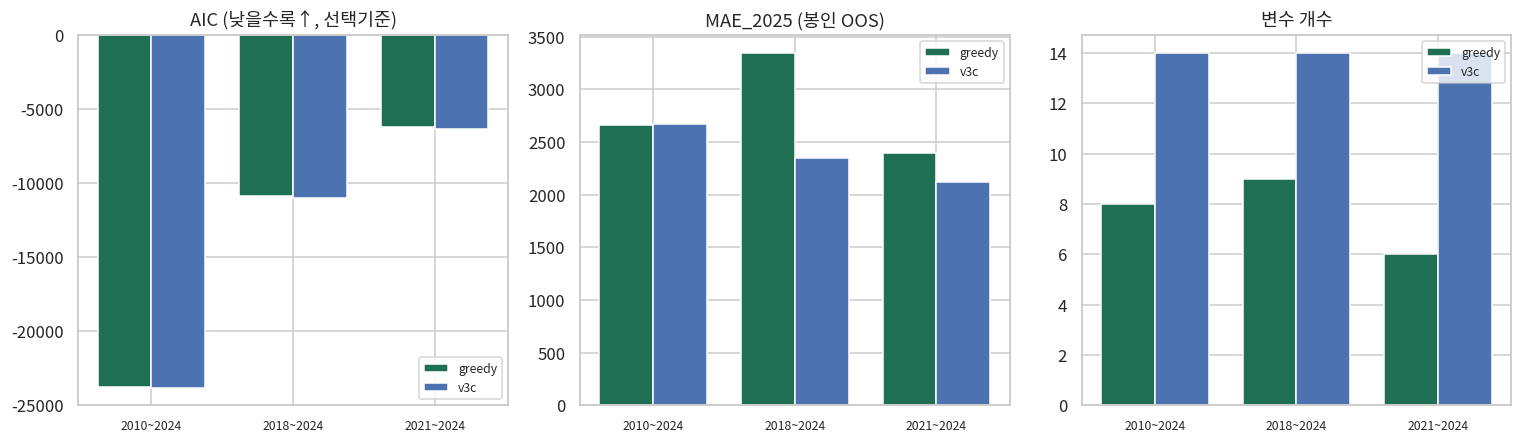

   window             model  n_exog       AIC  MAE_2025  MAPE_2025_%  dAIC_vs_v3c  dMAE_vs_v3c
2010~2024 greedy_discovered       8 -23751.85   2665.52         3.65        79.03        -5.46
2010~2024      v3c_baseline      14 -23830.88   2670.98         3.63         0.00         0.00
2018~2024 greedy_discovered       9 -10891.54   3346.71         4.38       109.66      1000.39
2018~2024      v3c_baseline      14 -11001.20   2346.32         3.17         0.00         0.00
2021~2024 greedy_discovered       6  -6181.31   2393.00         3.26       169.30       269.67
2021~2024      v3c_baseline      14  -6350.62   2123.33         2.93         0.00         0.00


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
metrics = [("AIC", "AIC (낮을수록↑, 선택기준)"),
           ("MAE_2025", "MAE_2025 (봉인 OOS)"),
           ("n_exog", "변수 개수")]
x = np.arange(len(WINS)); wbar = 0.38
for ax, (col, title) in zip(axes, metrics):
    gd = [summ[(summ.window == w) & (summ.model == "greedy_discovered")][col].iloc[0] for w in WINS]
    v3 = [summ[(summ.window == w) & (summ.model == "v3c_baseline")][col].iloc[0] for w in WINS]
    ax.bar(x - wbar/2, gd, wbar, label="greedy", color="#1f6f54")
    ax.bar(x + wbar/2, v3, wbar, label="v3c", color="#4c72b0")
    ax.set_xticks(x); ax.set_xticklabels(WINS, fontsize=8)
    ax.set_title(title)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

cols = ["window", "model", "n_exog", "AIC", "MAE_2025", "MAPE_2025_%", "dAIC_vs_v3c", "dMAE_vs_v3c"]
print(summ[cols].round(2).to_string(index=False))

## 결론

**1. 전 window 공통 견고핵심 (p<0.001).** `is_holiday`(−, 휴일 수요감소), `ss_day`(태양복사),
`hdd_18_ma7`+`hdd_18_sq`(난방·비선형), 냉방 도일항 1개, `hm_avg`(습도). 세 구간 모두에서
강하게 선택 → 기간과 무관한 구조적 동인. v3c의 기상·달력 핵심과 일치한다.

**2. 공선 클러스터는 대표 1개로 붕괴.** 냉방항이 window마다 `cdd_18_ma7`/`cdd_18`/`cdd_18_ma3`로
바뀌는 것은 VIF 게이트가 공선 형제 중 하나만 통과시키기 때문(어느 형제가 이기는지는 기간 노이즈).
계획에서 예측한 '클러스터 → 대표 1~2개' 거동이 그대로 재현됨.

**3. 추세항은 한계 신호가 미약.** `pop_total`은 어느 window에서도 미선택. `ip_total`(2018~)·
`ev_stock`(2010~)은 검색(maxiter=50) 마진에서 들어왔으나 **완전수렴(maxiter=200) 재적합 시
p=0.17·0.82로 비유의** — 즉 검색-근사 artifact다. 추세는 SARIMA 적분항이 이미 흡수.

**4. 전기차 — EV 민감도 결론 재확인.** `ev_flow`는 전 window 미선택. `ev_stock`은 2010~에서만,
그것도 **다른 추세항(pop_total/ip_total)이 선택되지 않은 상태의 저-VIF 추세 *대체재*** 로
잠깐 들어왔을 뿐이고 수렴 후 p=0.823로 사라진다. 독립 신호가 아니라 추세 공선의 잔향 —
`2026-05-30_1600` 민감도 결론(EV 무신호, 본모델 미포함)을 **세 기간 모두에서** 뒷받침.

**5. greedy는 v3c를 못 이김(정상).** AIC-from-empty + 엄격 게이트는 보수적·근시안적이라
v3c보다 AIC가 높고(덜 음수), 짧은 window(2018·2021)의 봉인 2025 MAE에서 뒤진다
(과적합 아니라 변수 부족). 전체 window(2010~)에선 8개 변수로 v3c(14개) MAE를 거의 동률로
맞춤 → v3c에 다소의 잉여는 있으나 해롭지 않고 짧은 기간 일반화에 도움. **본모델 v3c 유지가
타당**함을 독립적으로 재확인했다.

> 방법론 주의: 선택은 AIC+p+VIF(학습 내)로만 구동했고 2025 MAE는 비게이트 확인용 —
> 홀드아웃 봉인. 본모델·기존 노트북·exog 산출물 불변.
